# Практическая работа №7

## Случайный лес — Вариант B

**Датасет:** Palmer Penguins

**Цель:** сравнить одиночное дерево решений со случайным лесом, подобрать гиперпараметры через кросс-валидацию и исследовать важность признаков.

**Целевая переменная:** species — вид пингвина (Adelie, Chinstrap или Gentoo).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (
    train_test_split,
    GridSearchCV,
    StratifiedKFold,
    cross_val_score
)

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.base import clone

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)

In [2]:
df = pd.read_csv("../data/penguins.csv")

display(df.head())

print("Размер датасета:", df.shape)
print("\nПропущенные значения:")
print(df.isnull().sum())

print("\nКоличество пингвинов каждого вида:")
print(df["species"].value_counts())

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,MALE
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,FEMALE
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,FEMALE
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,FEMALE


Размер датасета: (344, 7)

Пропущенные значения:
species               0
island                0
bill_length_mm        2
bill_depth_mm         2
flipper_length_mm     2
body_mass_g           2
sex                  11
dtype: int64

Количество пингвинов каждого вида:
species
Adelie       152
Gentoo       124
Chinstrap     68
Name: count, dtype: int64


### Первичный анализ данных

Датасет Palmer Penguins содержит три вида пингвинов: Adelie, Chinstrap и Gentoo.

В данных представлены числовые характеристики и категориальные признаки. В некоторых столбцах имеются пропущенные значения.

В работе необходимо определить вид пингвина с помощью алгоритмов классификации и сравнить их качество.

In [3]:
numeric_features = [
    "bill_length_mm",
    "bill_depth_mm",
    "flipper_length_mm",
    "body_mass_g"
]

categorical_features = [
    "island",
    "sex"
]

features = numeric_features + categorical_features

X = df[features].copy()
y = df["species"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Train:", X_train.shape)
print("Test:", X_test.shape)

Train: (275, 6)
Test: (69, 6)


### Подготовка данных

Данные разделены на обучающую (80%) и тестовую (20%) выборки.

Используется стратификация для сохранения пропорций трёх видов пингвинов.

Для обучения используются шесть признаков. Целевая переменная species исключена из входных данных.

Предобработка будет выполняться внутри Pipeline, чтобы исключить утечку информации из тестовой выборки.

In [4]:
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(
        strategy="constant",
        fill_value="Unknown"
    )),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore"
    ))
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features)
])

print("Pipeline предобработки создан!")

Pipeline предобработки создан!


In [5]:
tree_model = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("classifier", DecisionTreeClassifier(
        random_state=42
    ))
])

tree_model.fit(X_train, y_train)

tree_pred = tree_model.predict(X_test)

print("Дерево решений обучено!")

Дерево решений обучено!


In [6]:
forest_default = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        random_state=42
    ))
])

forest_default.fit(X_train, y_train)

forest_pred = forest_default.predict(X_test)

print("Случайный лес обучен!")

Случайный лес обучен!


### Сравнение алгоритмов

DecisionTreeClassifier использует одно дерево решений. Оно может хорошо обучиться на тренировочных данных, но бывает чувствительным к их изменениям.

RandomForestClassifier объединяет предсказания многих деревьев, используя случайные подвыборки объектов и признаков.

В базовой модели используются 100 деревьев. Это стандартное отправное значение, которое далее сравнивается с другими вариантами при настройке гиперпараметров.

In [7]:
forest_pipeline = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("classifier", RandomForestClassifier(
        random_state=42
    ))
])

param_grid = {
    "classifier__n_estimators": [50, 100, 150],
    "classifier__max_depth": [3, 5, 10],
    "classifier__min_samples_leaf": [1, 2, 4]
}

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

grid_search = GridSearchCV(
    forest_pipeline,
    param_grid,
    cv=cv,
    scoring="f1_macro",
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

best_forest = grid_search.best_estimator_

print("Лучшие параметры:")
print(grid_search.best_params_)

print("\nЛучший Macro F1 на CV:")
print(round(grid_search.best_score_, 3))

Лучшие параметры:
{'classifier__max_depth': 5, 'classifier__min_samples_leaf': 1, 'classifier__n_estimators': 100}

Лучший Macro F1 на CV:
0.983


### Подбор гиперпараметров

Для настройки Random Forest применяется GridSearchCV с пятикратной стратифицированной кросс-валидацией.

Проверяются разные значения количества деревьев, максимальной глубины и минимального размера листа.

Для выбора модели используется Macro F1, поскольку в датасете три класса с неодинаковым количеством объектов.

Подбор параметров выполняется только на обучающей выборке.

In [8]:
def evaluate_model(name, model):
    pred = model.predict(X_test)

    return {
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(
            y_test, pred, average="macro", zero_division=0
        ),
        "Recall": recall_score(
            y_test, pred, average="macro", zero_division=0
        ),
        "F1": f1_score(
            y_test, pred, average="macro", zero_division=0
        )
    }

comparison = pd.DataFrame([
    evaluate_model("Decision Tree", tree_model),
    evaluate_model("Random Forest Default", forest_default),
    evaluate_model("Random Forest Tuned", best_forest)
])

display(comparison.round(3))

,Model,Accuracy,Precision,Recall,F1
0,Decision Tree,1.0,1.0,1.0,1.0
1,Random Forest Default,1.0,1.0,1.0,1.0
2,Random Forest Tuned,1.0,1.0,1.0,1.0


### Сравнение качества моделей

В работе сравниваются три модели: одиночное дерево решений, случайный лес с базовыми параметрами и настроенный случайный лес.

Для оценки используются Accuracy, Precision, Recall и Macro F1.

Macro F1 позволяет оценивать качество по всем видам пингвинов, не отдавая преимущество наиболее многочисленному классу.

Все три модели проверяются на одной тестовой выборке, поэтому результаты можно непосредственно сравнивать.

In [9]:
importance = permutation_importance(
    best_forest,
    X_train,
    y_train,
    scoring="f1_macro",
    n_repeats=10,
    random_state=42,
    n_jobs=-1
)

importance_df = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": importance.importances_mean
}).sort_values("Importance", ascending=False)

display(importance_df)

,Feature,Importance
4,island,0.335901
0,bill_length_mm,0.217597
1,bill_depth_mm,0.009348
2,flipper_length_mm,0.007908
3,body_mass_g,0.005805
5,sex,0.005695


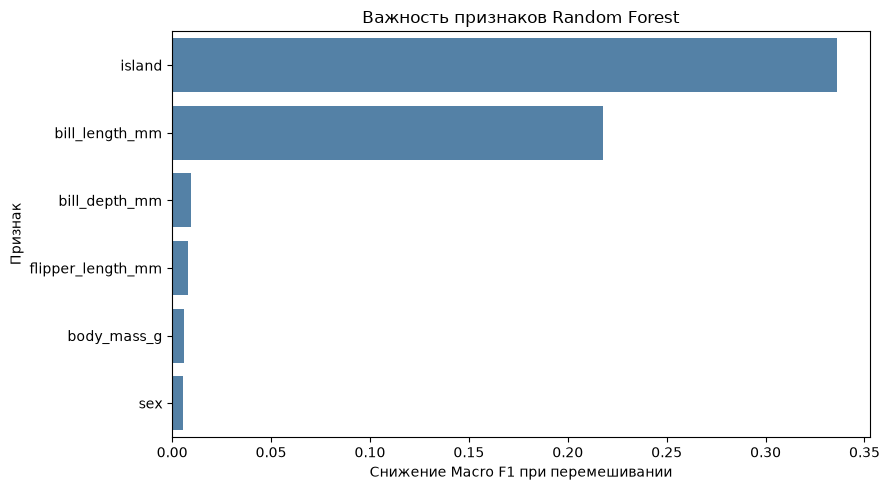

In [10]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=importance_df,
    x="Importance",
    y="Feature",
    color="steelblue"
)

plt.title("Важность признаков Random Forest")
plt.xlabel("Снижение Macro F1 при перемешивании")
plt.ylabel("Признак")

plt.tight_layout()
plt.show()

### Анализ важности признаков

Важность признаков рассчитана методом permutation importance.

Метод оценивает, насколько уменьшается качество модели при случайном перемешивании значений отдельного признака.

Высокая важность означает, что модель сильно зависит от этого признака.

Однако важность не доказывает причинно-следственную связь. Кроме того, коррелирующие признаки могут частично заменять друг друга.

In [11]:
least_important = importance_df.tail(2)["Feature"].tolist()

reduced_features = [
    col for col in features
    if col not in least_important
]

print("Удаляемые признаки:", least_important)
print("Оставшиеся признаки:", reduced_features)

Удаляемые признаки: ['body_mass_g', 'sex']
Оставшиеся признаки: ['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'island']


In [12]:
reduced_numeric = [
    f for f in numeric_features
    if f in reduced_features
]

reduced_categorical = [
    f for f in categorical_features
    if f in reduced_features
]

transformers = []

if reduced_numeric:
    transformers.append(
        ("num", clone(numeric_pipeline), reduced_numeric)
    )

if reduced_categorical:
    transformers.append(
        ("cat", clone(categorical_pipeline), reduced_categorical)
    )

reduced_preprocessor = ColumnTransformer(transformers)

reduced_forest = Pipeline([
    ("preprocessor", reduced_preprocessor),
    ("classifier", clone(
        best_forest.named_steps["classifier"]
    ))
])

In [13]:
cv_full = cross_val_score(
    clone(best_forest),
    X_train,
    y_train,
    cv=cv,
    scoring="f1_macro",
    n_jobs=-1
)

cv_reduced = cross_val_score(
    reduced_forest,
    X_train[reduced_features],
    y_train,
    cv=cv,
    scoring="f1_macro",
    n_jobs=-1
)

feature_comparison = pd.DataFrame({
    "Model": ["Все признаки", "Сокращённый набор"],
    "Macro_F1_CV": [
        cv_full.mean(),
        cv_reduced.mean()
    ],
    "Std_CV": [
        cv_full.std(),
        cv_reduced.std()
    ],
    "Features": [
        len(features),
        len(reduced_features)
    ]
})

display(feature_comparison.round(3))

,Model,Macro_F1_CV,Std_CV,Features
0,Все признаки,0.983,0.015,6
1,Сокращённый набор,0.979,0.022,4


### Эксперимент по сокращению признаков

Для эксперимента выбраны два признака с наименьшими значениями permutation importance.

На сокращённом наборе обучается новый случайный лес с теми же гиперпараметрами, что и настроенная модель.

Качество сравнивается через пятикратную кросс-валидацию по метрике Macro F1.

Если сокращённая модель показывает сопоставимый результат, удаление признаков может быть допустимо. Однако для окончательного решения необходима дополнительная проверка устойчивости результата.

In [14]:
use_reduced = cv_reduced.mean() >= cv_full.mean() - 0.01

if use_reduced:
    final_model = clone(reduced_forest)
    final_features = reduced_features
else:
    final_model = clone(best_forest)
    final_features = features

final_model.fit(
    X_train[final_features],
    y_train
)

final_pred = final_model.predict(X_test)

print("Итоговые признаки:", final_features)

print("Количество деревьев:",
      final_model.named_steps["classifier"].n_estimators)

print("\nИтоговые метрики:")
print(classification_report(
    y_test,
    final_pred,
    zero_division=0
))

Итоговые признаки: ['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'island']
Количество деревьев: 100

Итоговые метрики:
              precision    recall  f1-score   support

      Adelie       1.00      0.97      0.98        30
   Chinstrap       0.93      1.00      0.97        14
      Gentoo       1.00      1.00      1.00        25

    accuracy                           0.99        69
   macro avg       0.98      0.99      0.98        69
weighted avg       0.99      0.99      0.99        69



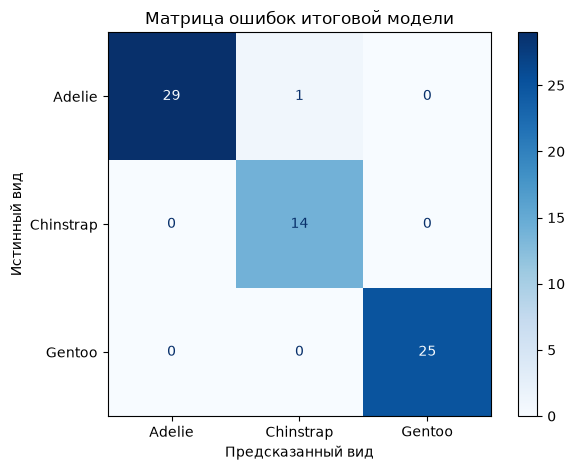

In [15]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    final_pred,
    display_labels=["Adelie", "Chinstrap", "Gentoo"],
    cmap="Blues"
)

plt.title("Матрица ошибок итоговой модели")
plt.xlabel("Предсказанный вид")
plt.ylabel("Истинный вид")
plt.tight_layout()
plt.show()

## Итоговый отчёт

1. В работе использован датасет Palmer Penguins для классификации трёх видов пингвинов.

2. Обучены DecisionTreeClassifier, базовый RandomForestClassifier и RandomForestClassifier с подобранными гиперпараметрами.

3. Гиперпараметры n_estimators, max_depth и min_samples_leaf настроены с помощью GridSearchCV и пятикратной кросс-валидации.

4. Модели сравнивались по Accuracy, Precision, Recall и Macro F1. Основной метрикой выбрана Macro F1, поскольку классы представлены неравномерно.

5. Построен график важности признаков с помощью permutation importance.

6. Выполнен эксперимент по удалению двух наименее важных признаков и проведено сравнение полного и сокращённого наборов.

7. Итоговая модель проверена на тестовой выборке. Построена матрица ошибок.

### Заключение

Random Forest объединяет множество деревьев решений и помогает уменьшить зависимость результата от отдельного дерева.

Подбор гиперпараметров позволяет управлять сложностью модели. Анализ важности признаков помогает определить, какие характеристики наиболее полезны для классификации пингвинов.

Окончательный выбор модели и признаков должен основываться на метриках и результатах проведённого эксперимента.